(299, 299)
(299, 299)
(299, 299)
(1023, 680)
(1023, 680)
(299, 299)
(4288, 2848)
(4288, 2848)
(299, 299)


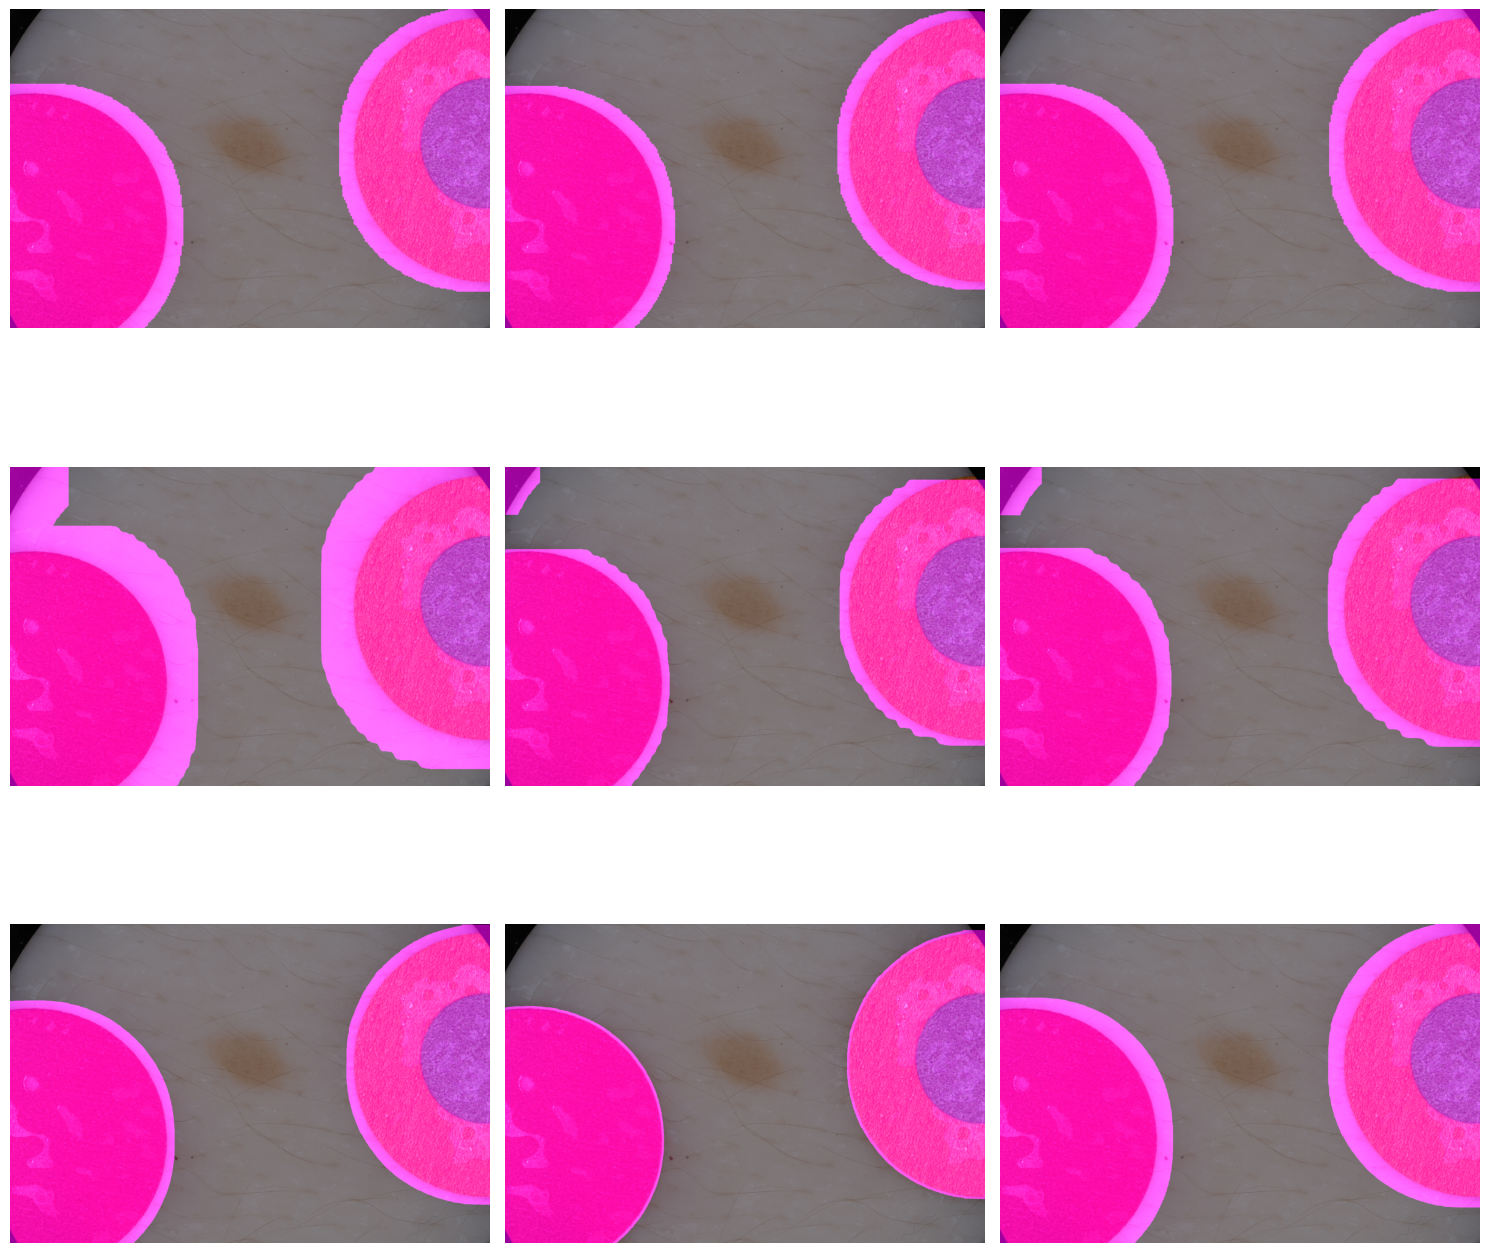

In [6]:
from PIL import Image
import os
import sys

# Add the project root directory to sys.path
project_root = os.path.abspath("..")  # Adjust this path if needed
if project_root not in sys.path:
    sys.path.insert(0, project_root)

from utils import dilate_mask, mask_on_image, plot_grid

def convert_img_id(img_id):
    # 55292 -> ISIC_0055292.jpg
    # 10 -> ISIC_0000010.jpg
    return f"ISIC_{str(img_id).zfill(7)}.jpg"


# path to output directory
raw_dir = "/workspace/datasets/ISIC19/raw"
gt_seg_dir = "/workspace/datasets/ISIC19/segmentation"
output_dir = "/workspace/home/pipeline_outputs/ISIC2019"


# get dilated segmentation and mask over image

def get_dilated_mask_over_img(mask_path, kernel_size, iterations, size=None):
    mask = (
            Image.open(mask_path)
            .convert("L")
            .point(lambda x: 255 if x > 128 else 0)
        )
    if size:
        mask = mask.resize(size)
    print(mask.size)
    dilated_mask = dilate_mask(mask, kernel_size, iterations).resize(img.size)
    mask_over_img = mask_on_image(img, dilated_mask)
    return mask_over_img


img_id = 694
img_id = convert_img_id(img_id)
img_path = f"{raw_dir}/{img_id}"
img = Image.open(img_path)

mask_path_gt = f"{gt_seg_dir}/{img_id}"
dilated_gt =  get_dilated_mask_over_img(mask_path_gt, 5, 5)
dilated_gt2 =  get_dilated_mask_over_img(mask_path_gt, 5, 4)
dilated_gt3 =  get_dilated_mask_over_img(mask_path_gt, 5, 5, (299,299))


mask_path_dito = f"{output_dir}/0004/seg/{img_id}"
dilated_dito =  get_dilated_mask_over_img(mask_path_dito, 15, 10)
dilated_dito2 =  get_dilated_mask_over_img(mask_path_dito, 5, 10)
dilated_dito3 =  get_dilated_mask_over_img(mask_path_dito, 5, 5, (299,299))


mask_path_rmbg = f"{output_dir}/0020/seg/{img_id}"
dilated_rmbg =  get_dilated_mask_over_img(mask_path_rmbg, 15, 10)
dilated_rmbg2 =  get_dilated_mask_over_img(mask_path_rmbg, 5, 10)
dilated_rmbg3 =  get_dilated_mask_over_img(mask_path_rmbg, 5, 5, (299,299))



plot_grid([dilated_gt, dilated_gt2, dilated_gt3, dilated_dito, dilated_dito2, dilated_dito3, dilated_rmbg, dilated_rmbg2, dilated_rmbg3], ncols=3)

 